# Yarkovsky drift on (101955) Bennu

**The question.** A small asteroid absorbs sunlight and re-radiates it as heat a little later, from
the afternoon side. That thermal recoil — the **Yarkovsky effect** — is a tiny, steady push along
the orbit that makes the semimajor axis drift by a few hundred metres per year. It cannot be
measured in a lab; it shows up only as a slow, accumulating mismatch between a gravity-only orbit
and decades of astrometry.

Bennu, the OSIRIS-REx target, is the best-measured case. Can PyRoOrb find its drift
from the public astrometry alone, and how close does it come to the spacecraft-era value?

PyRoOrb models the push as a transverse acceleration $A_2\,(1\,\mathrm{au}/r)^2$ (the Marsden
form, with $A_2$ in au/day²). It does not assume one: every fit of a low-perihelion asteroid tries
gravity-only, radial (solar radiation pressure) and transverse (Yarkovsky) models and keeps one only
when the data demand it (a BIC margin plus an F-test).

In [1]:
# Load the PyRoOrb settings file (.env: data folders) before the engine is imported.
from pyroorb.envfile import load_env_file
load_env_file()

import warnings
import numpy as np
import matplotlib.pyplot as plt
import pyroorb

# Future UTC dates make astropy warn that leap seconds are not yet known; harmless here.
warnings.filterwarnings("ignore", message=".*dubious year.*")
plt.rcParams.update({"figure.figsize": (8, 4.5), "figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": 0.3})
print("PyRoOrb", pyroorb.__version__)

PyRoOrb 0.9.0


## 1. Fetch and fit

One call fetches the optical astrometry from the MPC (and Bennu's radar delay/Doppler from JPL);
one call fits it. Model selection runs automatically.

In [2]:
obs = pyroorb.fetch_observations("101955")
fit = pyroorb.fit_orbit(obs, designation="101955")

print(f"{fit.n_observations()} of {fit.n_total_observations()} optical observations kept, "
      f"plus {len(obs.meta['radar'])} radar; arc {fit.arc_length_days() / 365.25:.1f} yr, "
      f"rms {fit.rms_residual():.3f}\"")
print("force model:", fit.force_model, "| non-gravitational model chosen:", fit.nongrav_model)

A2 = fit.nongrav_params["A2"]
lo, hi = fit.rational_nongrav_intervals()["A2"]
print(f"A2 = {A2:.4e}  (-{lo:.2e} / +{hi:.2e}) au/day^2   ->  {abs(A2) / lo:.0f} sigma from zero")

592 of 603 optical observations kept, plus 29 radar; arc 25.6 yr, rms 0.432"
force model: ASSIST(DE440+GR) | non-gravitational model chosen: yarkovsky
A2 = -4.3985e-14  (-2.42e-16 / +2.42e-16) au/day^2   ->  181 sigma from zero


## 2. Why that model? The model comparison

The fit keeps a record of every model it tried (`fit.nongrav_discovery` — internal API, may change).
Each trial is a full re-fit on the same observations; the transverse model wins on the F-test while
the radial-only model buys nothing.

In [3]:
disc = fit.nongrav_discovery["asteroid"]
print(f"{'model':10s} {'rms (\")':>8s} {'F-test p':>10s}  z-scores")
print(f"{'gravity':10s} {disc['rms0']:8.3f}")
for name, m in disc["compare"].items():
    z = ", ".join(f"{k}={v:.1f}" for k, v in m["z"].items())
    print(f"{name:10s} {m['rms']:8.3f} {m['pval']:10.1e}  {z}")
print("chosen:", disc["model"])

model       rms (")   F-test p  z-scores
gravity       0.590
srp           0.588    1.0e+00  A1=2.7
yarkovsky     0.581    4.8e-14  A2=8.2
srp2          0.579    2.9e-14  A1=2.5, A2=8.2
chosen: yarkovsky


## 3. What gravity alone gets wrong: the radar

Bennu was ranged by Arecibo and Goldstone in 1999, 2005 and 2011. A radar delay pins the distance
to a few hundred metres or better, so a few hundred metres of unmodelled drift per year is glaring.
We re-fit the same observations with non-gravitational discovery switched off
(`auto_nongrav=False` on the internal `fit_object.fit_orbit`). Then we ask two questions: does the
radar fit that orbit, and how far apart are the two orbits in Earth–Bennu distance?

gravity only: radar refit degraded the optical fit 0.54 -> 0.92 sigma; kept the optical orbit
Yarkovsky   : radar joined the fit, median |O-C|/sigma = 0.15


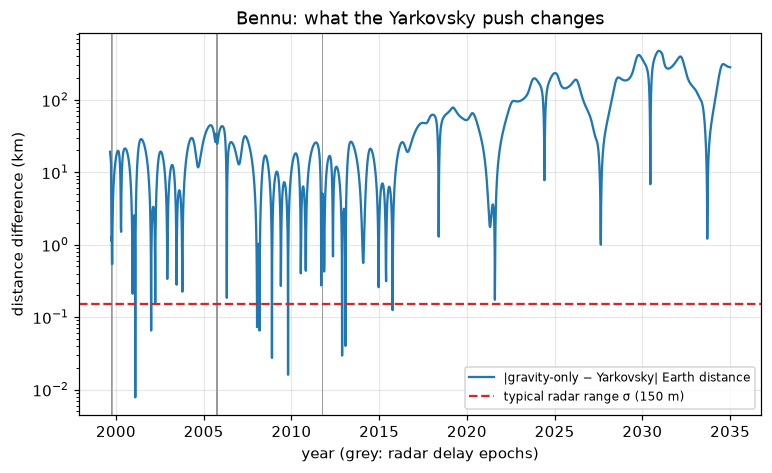

In [4]:
from astropy.time import Time
from pyroorb import fit_object

grav = fit_object.fit_orbit(list(obs), pyroorb.obscodes(), desig="101955", meta=obs.meta,
                            auto_nongrav=False)
print("gravity only:", grav.radar.get("note") or "radar joined the fit")
print("Yarkovsky   :", "radar joined the fit, median |O-C|/sigma = "
      f"{np.median([abs(r['z']) for r in fit.radar['rows'] if r['included']]):.2f}")

# Earth-Bennu distance under each orbit, 1999-2035 (public ephemeris call; site 500 = geocentre)
eph = {name: pyroorb.ephemeris(f, "1999-09-01", "2035-01-01", step=5.0, full=False)
       for name, f in (("grav", grav), ("yark", fit))}
t = Time([r["jd_utc"] for r in eph["yark"]], format="jd").decimalyear
dkm = np.abs([(g["delta_au"] - y["delta_au"]) * 1.495978707e8 for g, y in zip(eph["grav"], eph["yark"])])

delay = [r for r in obs.meta["radar"] if r["kind"] == "delay"]
range_sigma_km = np.median([r["sigma"] for r in delay]) * 299792.458 / 2   # delay sigma in seconds

fig, ax = plt.subplots()
ax.semilogy(t, dkm, label="|gravity-only − Yarkovsky| Earth distance")
ax.axhline(range_sigma_km, color="C3", ls="--", label=f"typical radar range σ ({range_sigma_km * 1000:.0f} m)")
for r in delay:
    ax.axvline(Time(r["jd_utc"], format="jd").decimalyear, color="0.6", lw=0.5, zorder=0)
ax.set_xlabel("year (grey: radar delay epochs)"); ax.set_ylabel("distance difference (km)")
ax.set_title("Bennu: what the Yarkovsky push changes"); ax.legend(fontsize=8); plt.show()

Both orbits fit the *optical* sky positions well, but at the radar epochs they disagree in distance
by far more than the radar's precision. When the gravity-only orbit is made to honour the radar, it
must pull the optical fit off (0.54σ → 0.92σ), and the engine refuses that compromise. With
$A_2$ the radar joins the fit at a fraction of a σ. Beyond the data the two orbits separate quickly.
That is why the drift matters for Bennu's 22nd-century impact assessment.

## 4. The perturbing asteroids matter

Bennu's published solutions integrate the pull of the largest main-belt asteroids. PyRoOrb's
default force model is the Sun, planets, Moon and Pluto (DE440) plus relativity; the 16 most massive
asteroids (JPL's `sb441-n16` kernel, ~616 MB, downloaded on first use) can be switched on. The
switch below flips a module setting — internal API, may change.

In [5]:
import pyroorb.force_assist as fa

fa.ASTEROIDS_PATH = fa.ensure_asteroid_kernel()         # whole-fit mode: 16 asteroid perturbers on
fit16 = pyroorb.fit_orbit(obs, designation="101955")
fa.ASTEROIDS_PATH = None                                 # back to the default force model

A2_16 = fit16.nongrav_params["A2"]
s16 = fit16.rational_nongrav_intervals()["A2"][0]
print(fit16.force_model, f"A2 = {A2_16:.4e} ± {s16:.1e} au/day^2  "
      f"({100 * (A2_16 / A2 - 1):+.1f}% vs planets only)")

ASSIST(DE440+GR+16ast) A2 = -4.4665e-14 ± 2.4e-16 au/day^2  (+1.5% vs planets only)


## 5. Compare with the published values

JPL's current Bennu orbit is fitted with a full thermal model driven by the OSIRIS-REx shape and
spin (its SBDB entry lists bulk density and area-to-mass ratio instead of an $A_2$), so the
model-independent number to compare is the **mean semimajor-axis drift**. For a transverse
$A_2 (r_0/r)^2$ the orbit-averaged Gauss equation gives
$\langle da/dt\rangle = 2A_2 r_0^2 / \big(n\,a^2(1-e^2)\big)$.

Published values: Chesley et al. (2014, Icarus 235, 5), ground-based optical + radar data,
$da/dt = (-19.0 \pm 0.1)\times10^{-4}$ au/Myr $= -284.2 \pm 1.5$ m/yr; Farnocchia et al. (2021,
Icarus 369, 114594), with OSIRIS-REx tracking, $da/dt = -284.6 \pm 0.2$ m/yr.

JPL SBDB orbit 118 non-grav parameters: {'AMRAT': '2.64e-06 ± 1.908E-7 m^2/kg', 'RHO': '1190 ± .892 kg/m^3'}
PyRoOrb, planets only           da/dt =  -274.7 ±  1.5 m/yr
PyRoOrb, + 16 asteroids         da/dt =  -279.0 ±  1.5 m/yr
Chesley+ 2014 (ground-based)    da/dt =  -284.2 ±  1.5 m/yr
Farnocchia+ 2021 (OSIRIS-REx)   da/dt =  -284.6 ±  0.2 m/yr


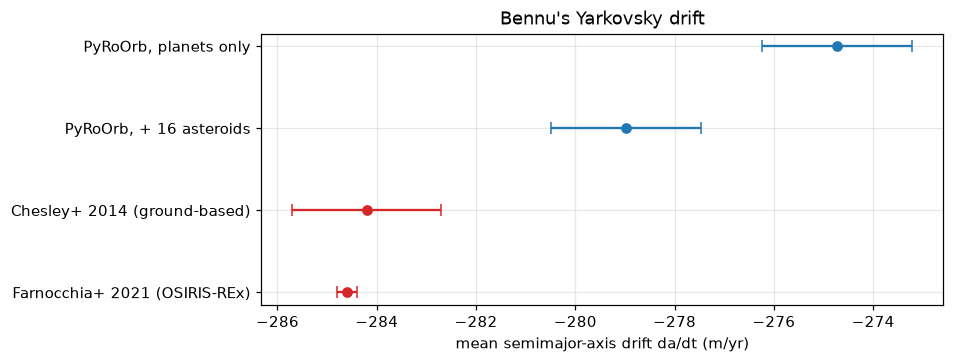

In [6]:
import json, urllib.request

AU_M = 1.495978707e11
def dadt_m_per_yr(a2, f):
    el = f.elements()                                     # a (au), e, n (deg/day), ...
    n, a, e = np.radians(el["n"]), el["a"], el["e"]
    return 2 * a2 / (n * a**2 * (1 - e**2)) * AU_M * 365.25

sbdb = json.load(urllib.request.urlopen("https://ssd-api.jpl.nasa.gov/sbdb.api?sstr=101955"))
print("JPL SBDB orbit", sbdb["orbit"]["orbit_id"], "non-grav parameters:",
      {p["name"]: f"{p['value']} ± {p['sigma']} {p['units']}" for p in sbdb["orbit"]["model_pars"]})

rows = [("PyRoOrb, planets only",       dadt_m_per_yr(A2, fit),     abs(dadt_m_per_yr(lo, fit))),
        ("PyRoOrb, + 16 asteroids",     dadt_m_per_yr(A2_16, fit16), abs(dadt_m_per_yr(s16, fit16))),
        ("Chesley+ 2014 (ground-based)", -284.2, 1.5),
        ("Farnocchia+ 2021 (OSIRIS-REx)", -284.6, 0.2)]
for name, v, s in rows:
    print(f"{name:31s} da/dt = {v:7.1f} ± {s:4.1f} m/yr")

fig, ax = plt.subplots(figsize=(8, 3.2))
for k, (name, v, s) in enumerate(rows):
    ax.errorbar(v, k, xerr=s, fmt="o", capsize=4, color="C0" if k < 2 else "C3")
ax.set_yticks(range(len(rows)), [r[0] for r in rows]); ax.invert_yaxis()
ax.set_xlabel("mean semimajor-axis drift da/dt (m/yr)")
ax.set_title("Bennu's Yarkovsky drift"); plt.show()

**Result.** From public astrometry alone, in seconds, PyRoOrb detects Bennu's drift at ~180σ and
lands within about 2–4% of the spacecraft-era value. Switching on the asteroid perturbers moves it
toward the published numbers.

**Honest caveat.** The formal uncertainties (±1–2 m/yr) are smaller than the remaining gap (~6–10
m/yr), so they are not the whole error budget. Unmodelled effects remain: JPL integrates hundreds of
perturbing asteroids, not 16; it uses a physical thermal model rather than a pure $1/r^2$
transverse term; and observation weighting differs. The density follows the drift: Chesley et al.
turned their $A_2$ into a pre-arrival bulk density of $1260 \pm 70$ kg/m³, and OSIRIS-REx later
measured $1190$ kg/m³. At fixed thermal properties, density scales as $1/|A_2|$, so a few-percent
error in $A_2$ is a few-percent error in density.